# 15 · Alpha 融合：把 A–E 变成连续因子，再合成一个 spread 预测

单个 idea 都太弱（D-019、D-022、D-025–D-028）。这里换一个角度：把每个 idea 抽象成**连续的 alpha 因子**，统一预测**同一个目标**——主力对（最近两张可交易合约）未来的 spread 收益，再把多个因子合成一个预测，最后用 v2 回测框架变现。协议见 D-030。

- **样本**：train 1986–2005（筛因子、拟合模型），validation 2006–2015（选模型、horizon、组合规则），test 2016–2026 只读一次。
- **全部是时序统计**：每个商品的因子只和它自己未来的 spread 收益比；截面组合只作为对照实验（各交易所 settle 时间不同）。
- **时点**：t 的 settle 出信号，t+1 成交；`[t, t+1]` 是论文时点，只作诊断。
- **计算**放在 `scripts/run_alpha.py`（`--stage select` / `--stage test`），本 notebook 只读结果、画图。

In [1]:
import json
import os
import pickle
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

In [2]:
import numpy as np
import pandas as pd
from IPython.display import display

from src import alpha_factors as af, alpha_figures as AF, alpha_models as M, alpha_portfolio as P, alpha_screen as S
from src import config, figures as F, horizon, plotstyle as ps, report

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
print("LaTeX text rendering:", ps.use())

OUT = config.OUTPUT_DIR / "alpha"
SEL = json.loads((OUT / "selection.json").read_text())
FACTORS = list(af.FACTORS)
BLOCK = SEL["block"]
ROOT_ORDER = ["CL", "CO", "HO", "XB", "NG", "C", "W", "S", "SM", "BO", "O", "RR",
              "SB", "KC", "CC", "CT", "JO", "LB", "LC", "FC", "LH", "GC", "SI", "HG"]

LaTeX text rendering: True


## 1. 十二个因子

每个 idea 抽象成 2–3 个连续分数，全部只用 t 及以前的 settle。符号保持原定义（例如 carry 为正 = backwardation），方向由模型在 train 上学，不再人为 flip。

| Idea | 因子 | 定义 |
|---|---|---|
| A carry | `a_carry`, `a_carry_dev` | 主力对年化 carry；减去自身 252 天均值 |
| B 曲线形状 | `b_curve_carry`, `b_rel_carry` | 前段减后段相邻 carry；主力对 carry 减相邻 carry 均值 |
| C 均值回复 | `c_z20`, `c_z60`, `c_rev5` | 连续 spread 指数的 −z（20/60 天）；−过去 5 天 spread 收益 |
| D 曲线动量 | `d_mom21`, `d_mom63`, `d_mom252` | 主力对过去 21/63/252 天累计 spread 收益 |
| E Nelson–Siegel | `e_dslope`, `e_dcurv` | NS slope / curvature 的一日变化 ÷ 价格水平 |

下图：因子之间的相关性（train，pooled）。同一 idea 内部高度相关，跨 idea 大多很低——这正是融合的价值所在。

In [3]:
panel = pd.read_parquet(OUT / "panel_select.parquet")
usable = panel.loc[panel["usable"]]
train = S.slice_period(usable, "train")
valid = S.slice_period(usable, "valid")
display(train[FACTORS].describe().T[["count", "mean", "std", "min", "max"]].round(4))

,count,mean,std,min,max
a_carry,88385.0,-0.0222,0.2678,-2.9896,4.0682
a_carry_dev,87342.0,-0.0015,0.2397,-2.0590,4.1653
b_curve_carry,88307.0,-0.0223,0.3004,-6.0271,3.8314
b_rel_carry,88385.0,-0.0121,0.1561,-2.8020,2.4220
c_z20,88050.0,0.1046,1.2817,-4.2485,4.2485
c_z60,87838.0,0.1407,1.3992,-7.5636,7.5688
c_rev5,88385.0,0.0001,0.0103,-0.2770,0.2486
d_mom21,88289.0,-0.0002,0.0192,-0.2887,0.2410
d_mom63,88010.0,-0.0008,0.0326,-0.3067,0.2922
d_mom252,86616.0,-0.0037,0.0715,-0.5204,0.3901


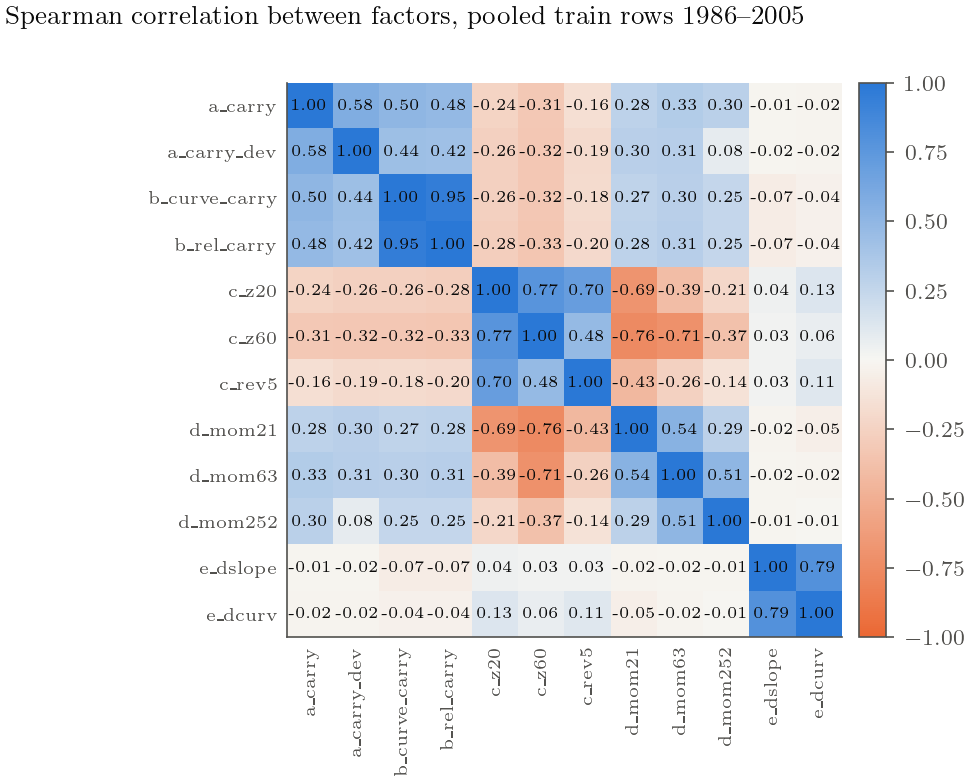

In [4]:
fig = AF.factor_correlation(train, FACTORS)
ps.save(fig, "alpha_factor_corr");

## 2. Day-block bootstrap：block 取多长

每个商品的 IC 在日期上自相关（因子持续、前向收益窗口重叠），普通 bootstrap 会低估标准误。做法：在**共同日历**上按 block 重抽日期，所有商品、所有因子共用同一组日期——这样跨商品平均 IC 的标准误也有效。

实验：block = 1, 5, 10, 21, 42, 63, 126 天。均值 IC 不随 block 变（重抽不改变估计量），**标准误先升后平**；取第一个落在平台（与 126 天的 SE 相差 10% 以内）的 block。

In [5]:
sens = pd.read_parquet(OUT / "block_sensitivity.parquet")
display(sens.loc[sens["root"].eq("ALL")].pivot(index="score", columns="block", values="se").round(4))
print("chosen block:", BLOCK, "days; at horizon h the block is max(block, h)")

block,1,5,10,21,42,63,126
score,,,,,,,
a_carry,0.0039,0.0067,0.0075,0.0075,0.0079,0.0081,0.0087
a_carry_dev,0.0040,0.0067,0.0075,0.0072,0.0072,0.0070,0.0071
b_curve_carry,0.0041,0.0066,0.0071,0.0077,0.0075,0.0075,0.0072
b_rel_carry,0.0040,0.0065,0.0071,0.0077,0.0074,0.0073,0.0070
c_rev5,0.0040,0.0059,0.0062,0.0064,0.0068,0.0066,0.0072
c_z20,0.0036,0.0059,0.0065,0.0069,0.0068,0.0065,0.0066
c_z60,0.0037,0.0060,0.0068,0.0070,0.0072,0.0068,0.0073
d_mom21,0.0038,0.0062,0.0072,0.0073,0.0070,0.0068,0.0071
d_mom252,0.0039,0.0066,0.0071,0.0070,0.0071,0.0071,0.0072


chosen block: 10 days; at horizon h the block is max(block, h)


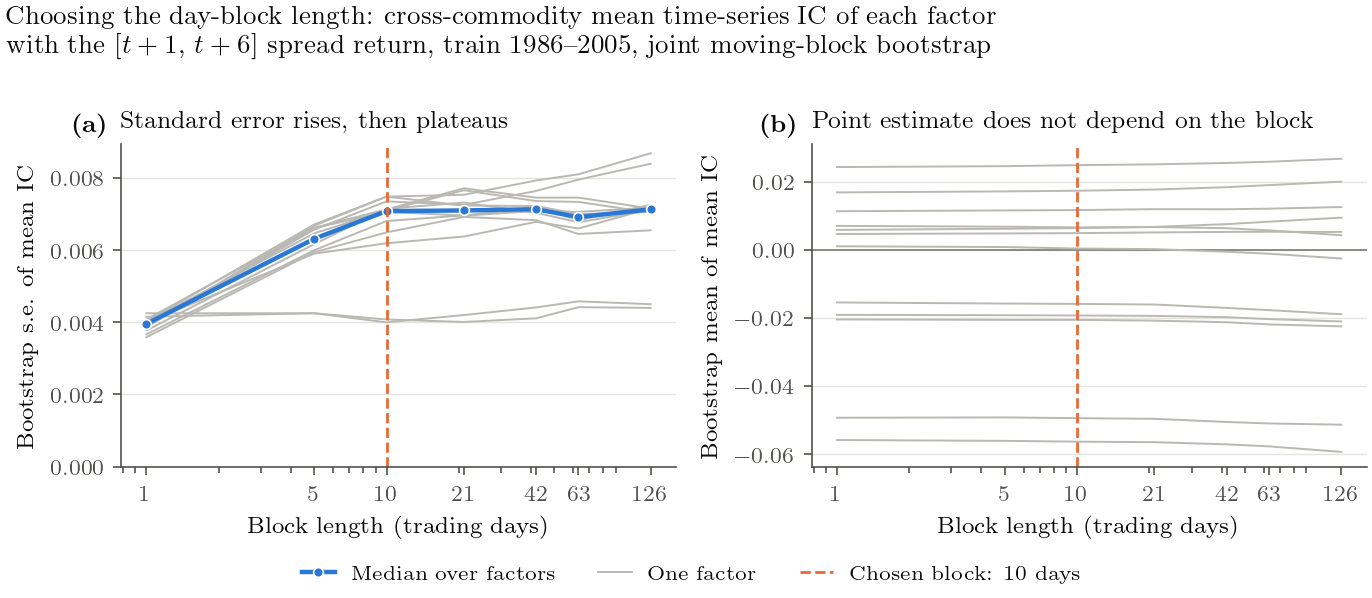

In [6]:
fig = AF.block_sensitivity(sens, BLOCK)
ps.save(fig, "alpha_block_length");

## 3. 因子筛选（train，每个 horizon 分别筛）

规则（预先登记）：在 ≥ 一半商品上显著（bootstrap p<0.05，且方向与跨商品均值一致）→ 通过；若通过的少于 3 个，再放宽为“跨商品均值 IC 的 95% CI 不含 0，且 ≥ 2/3 商品同号”。

In [7]:
screen = pd.read_parquet(OUT / "screen.parquet")
display(screen.pivot(index="score", columns="target", values="rule").reindex(FACTORS)[af.TARGETS])
for t in af.TARGETS:
    print(f"{t:9s}", SEL["features"][t])

target,fwd_0_1,fwd_1_2,fwd_1_3,fwd_1_6,fwd_1_11,fwd_1_22
score,,,,,,
a_carry,primary,fallback,fallback,fallback,fallback,fallback
a_carry_dev,primary,fallback,fallback,primary,primary,primary
b_curve_carry,,,,,fallback,fallback
b_rel_carry,primary,,,,fallback,fallback
c_z20,primary,fallback,fallback,fallback,fallback,fallback
c_z60,,,,,,
c_rev5,primary,fallback,fallback,fallback,fallback,fallback
d_mom21,,,,,,
d_mom63,,,,,,


fwd_0_1   ['a_carry', 'a_carry_dev', 'b_rel_carry', 'c_z20', 'c_rev5']
fwd_1_2   ['a_carry', 'a_carry_dev', 'c_z20', 'c_rev5']
fwd_1_3   ['a_carry', 'a_carry_dev', 'c_z20', 'c_rev5', 'e_dcurv']
fwd_1_6   ['a_carry', 'a_carry_dev', 'c_z20', 'c_rev5', 'e_dcurv']
fwd_1_11  ['a_carry', 'a_carry_dev', 'b_curve_carry', 'b_rel_carry', 'c_z20', 'c_rev5']
fwd_1_22  ['a_carry', 'a_carry_dev', 'b_curve_carry', 'b_rel_carry', 'c_z20', 'c_rev5']


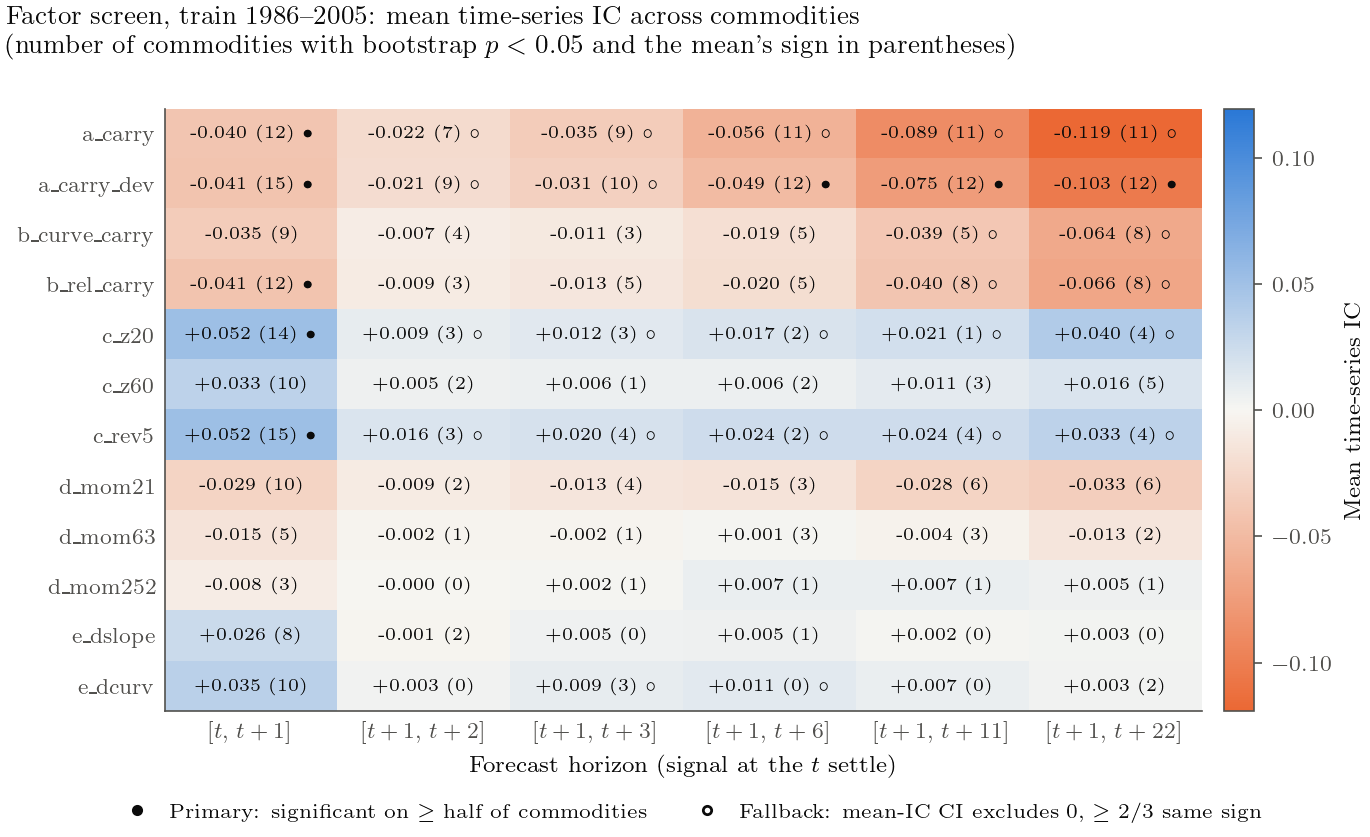

In [8]:
fig = AF.screen_heatmap(screen, FACTORS)
ps.save(fig, "alpha_screen");

最强因子在每个商品上的 IC 分布：`a_carry_dev` 对 `[t+1, t+6]`，每个商品一个竖直直方图，标出 bootstrap p 值。

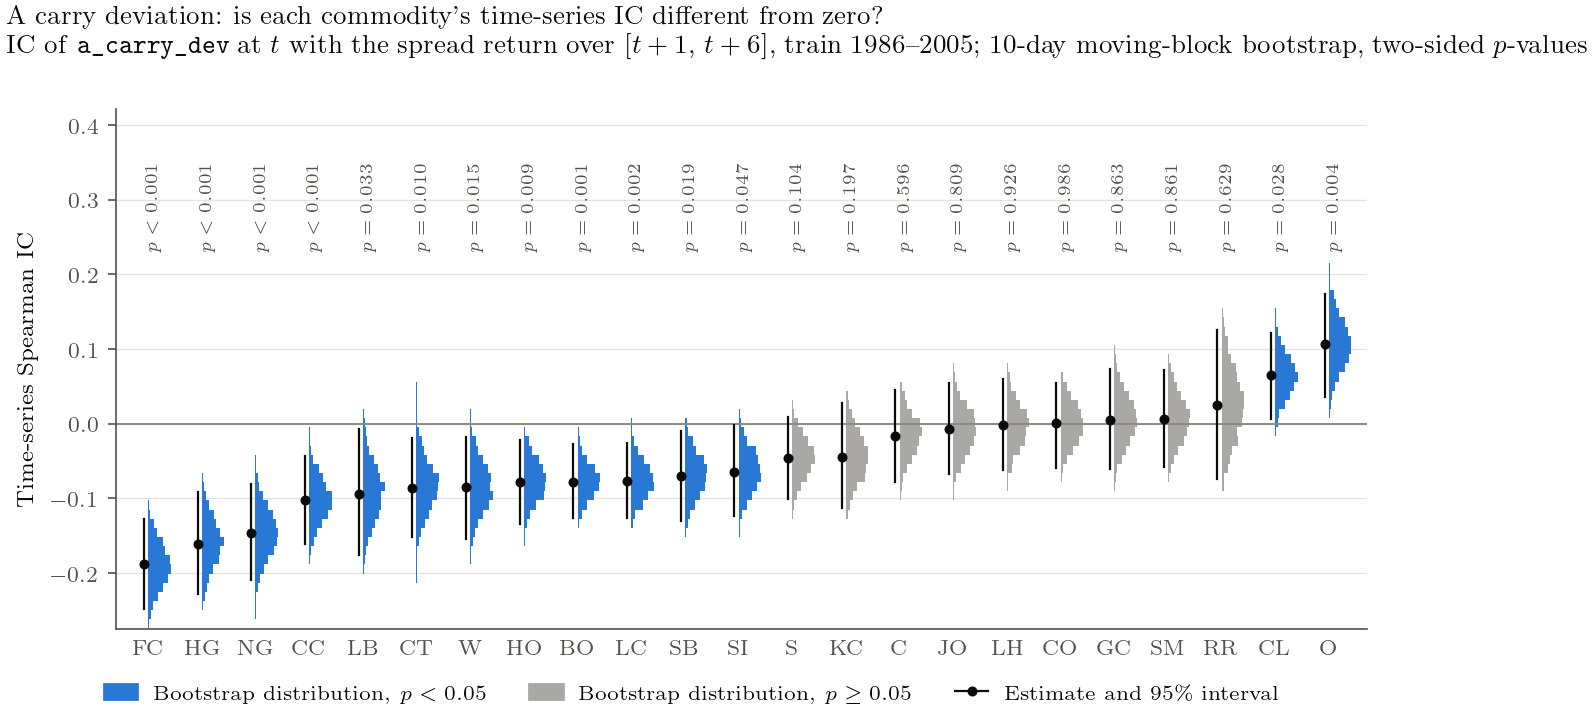

In [9]:
tgt = "fwd_1_6"
mats = S.rank_matrices(train, ["a_carry_dev"], tgt)
boot = S.joint_bootstrap(mats, ["a_carry_dev"], max(BLOCK, 5), n_boot=2000)
tab = S.ic_table(mats, boot, "a_carry_dev")
per = tab.loc[tab["root"].ne("ALL")]
draws = {r: boot["a_carry_dev"][1][:, i] for i, r in enumerate(mats["roots"]) if r in set(per["root"])}
fig = F.bootstrap_ic_distribution(per, draws, "A carry deviation", r"\texttt{a\_carry\_dev}",
                                  r"$[t+1,\,t+6]$, train 1986--2005", max(BLOCK, 5))
ps.save(fig, "alpha_root_ic_a_carry_dev");

## 4. 模型：OLS / Ridge / Lasso / ElasticNet / RF / XGBoost

所有商品 pooled 一起拟合；特征是因果缩放后的因子（缺失 → 0），目标是 ÷（滞后 60 天 spread 波动 × √窗口长度）后的前向 spread 收益。超参数固定，只给 Ridge、Lasso 各两档——调参不是重点。

模型在 train 上拟合，在 validation 上比较：指标是**预测与实现 spread 收益的跨商品平均时序 IC**。

In [10]:
msum = pd.read_parquet(OUT / "model_summary.parquet")
mpairs = pd.read_parquet(OUT / "model_pairs.parquet")
with open(OUT / "model_draws.pkl", "rb") as fh:
    mdraws = pickle.load(fh)
display(msum.pivot(index="model", columns="target", values="mean_ic").reindex(list(M.MODEL_ZOO))[af.TARGETS].round(4))
display(msum.pivot(index="model", columns="target", values="wins").reindex(list(M.MODEL_ZOO))[af.TARGETS])
print("selected:", SEL["models"])

target,fwd_0_1,fwd_1_2,fwd_1_3,fwd_1_6,fwd_1_11,fwd_1_22
model,,,,,,
ols,0.0176,0.0357,0.0448,0.0673,0.0955,0.1184
ridge_1e3,0.0177,0.0358,0.0451,0.0676,0.0961,0.1176
ridge_1e5,0.0208,0.0350,0.0497,0.0718,0.0855,0.1077
lasso_1e-3,0.0176,0.0362,0.0458,0.0682,0.0953,0.1178
lasso_1e-2,0.0163,0.0316,0.0449,0.0694,0.0805,0.1239
enet,0.0173,0.0325,0.0490,0.0711,0.0940,0.1199
rf,0.0250,0.0239,0.0247,0.0617,0.0822,0.1124
xgb,0.0205,0.0144,0.0173,0.0497,0.0860,0.1161


target,fwd_0_1,fwd_1_2,fwd_1_3,fwd_1_6,fwd_1_11,fwd_1_22
model,,,,,,
ols,1,2,2,1,1,1
ridge_1e3,2,2,3,2,1,1
ridge_1e5,5,2,2,1,0,0
lasso_1e-3,1,2,4,3,1,1
lasso_1e-2,0,1,2,1,0,5
enet,1,1,4,1,1,3
rf,5,1,1,1,0,0
xgb,0,0,0,0,0,0


selected: {'fwd_0_1': 'ridge_1e5', 'fwd_1_2': 'ols', 'fwd_1_3': 'lasso_1e-3', 'fwd_1_6': 'lasso_1e-3', 'fwd_1_11': 'ols', 'fwd_1_22': 'lasso_1e-2'}


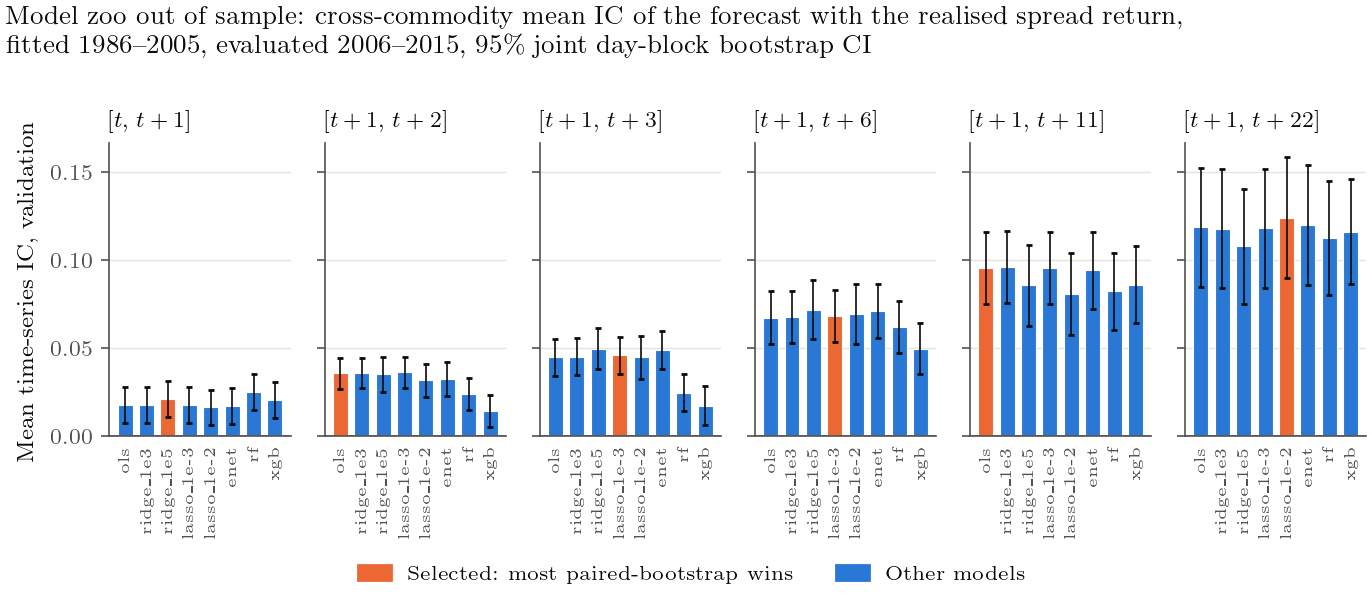

In [11]:
fig = AF.model_ic_by_horizon(msum, SEL["models"])
ps.save(fig, "alpha_model_ic");

### Paired bootstrap：model 减 model

每次重抽，所有模型用**同一组日期 block**，算各自的跨商品平均 IC 再相减——差值分布的 95% CI 全在 0 以上记一次“胜”。胜场最多的模型入选，平局取更简单的。下面以 `[t+1, t+6]` 为例。

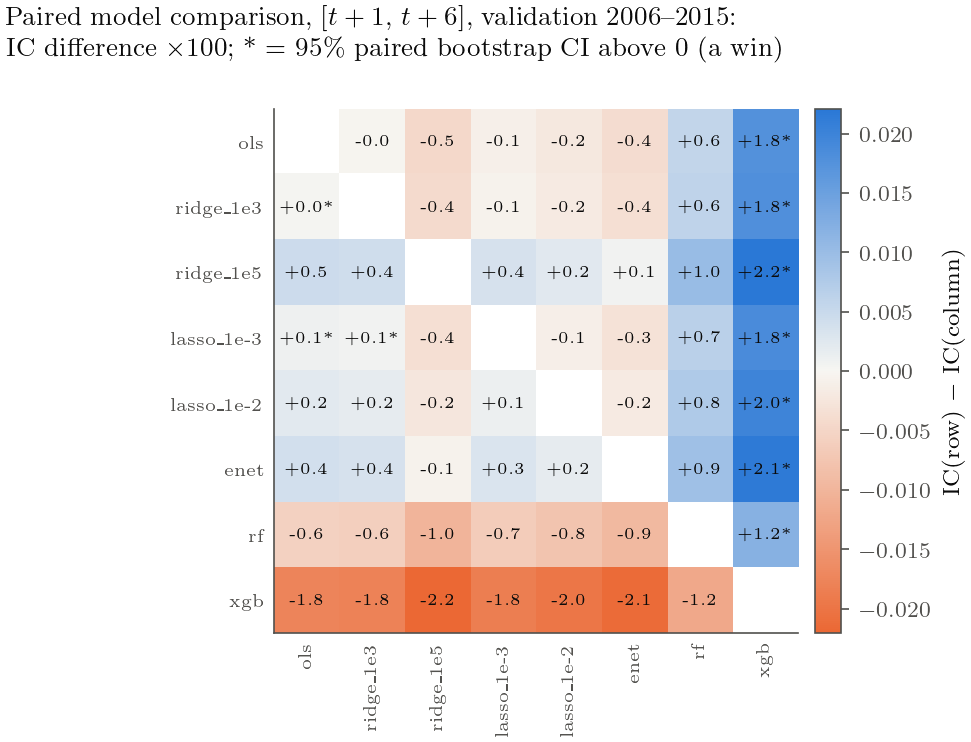

In [12]:
HEAD = "fwd_1_6"
fig = AF.model_win_matrix(mpairs, HEAD)
ps.save(fig, "alpha_model_wins");

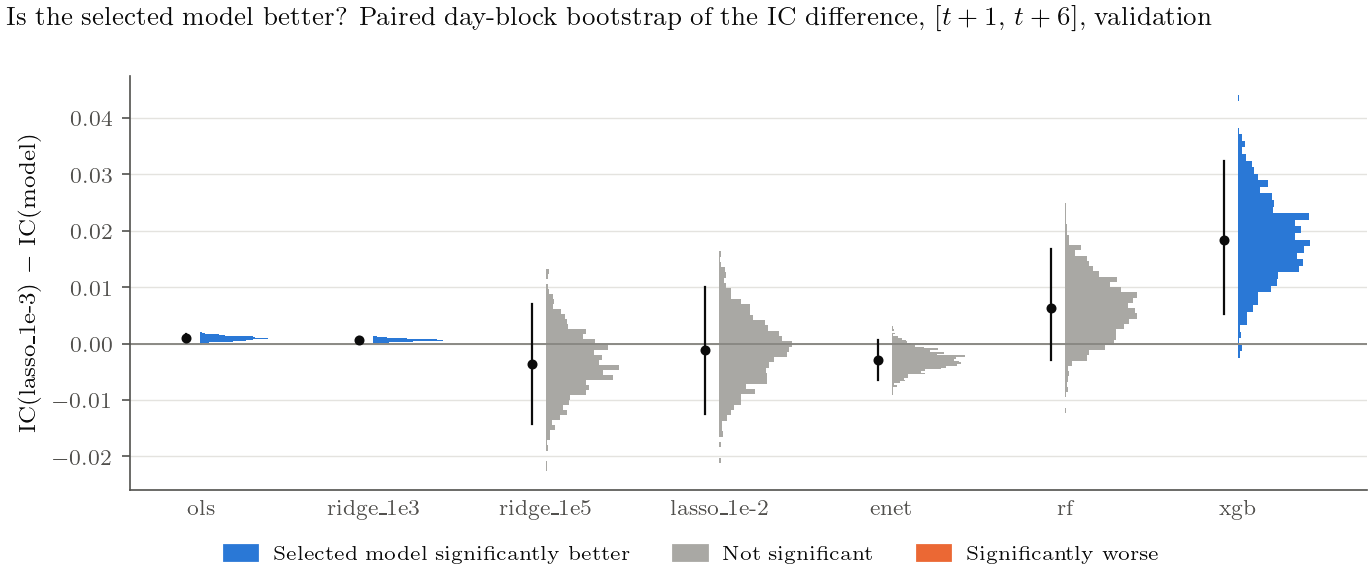

In [13]:
fig = AF.model_diff_distributions(mdraws[HEAD], SEL["models"][HEAD], HEAD)
ps.save(fig, "alpha_model_diff");

线性模型的系数（train）：方向和大小直接对应“哪个 idea 在贡献信息”。

In [14]:
coefs = pd.read_parquet(OUT / "coefficients.parquet").drop_duplicates(["factor", "target", "model"])
display(coefs.loc[coefs["model"].eq("ols")].pivot(index="factor", columns="target", values="value")
        .reindex(columns=af.TARGETS).round(4))

target,fwd_0_1,fwd_1_2,fwd_1_3,fwd_1_6,fwd_1_11,fwd_1_22
factor,,,,,,
a_carry,0.0095,0.0010,0.0093,0.0127,-0.0058,-0.0364
a_carry_dev,-0.0204,-0.0252,-0.0374,-0.0501,-0.0505,-0.0626
b_curve_carry,NaN,NaN,NaN,NaN,0.0513,0.0446
b_rel_carry,-0.0319,NaN,NaN,NaN,-0.0765,-0.0968
c_rev5,0.0124,0.0266,0.0389,0.0521,0.0397,-0.0012
c_z20,0.0334,-0.0173,-0.0299,-0.0386,-0.0316,0.0138
e_dcurv,NaN,NaN,0.0008,0.0007,NaN,NaN


## 5. 预测诊断（validation 2006–2015）

先看预测本身靠不靠谱，再谈变现：分箱图（预测的自身历史十分位 vs 实现收益）、IC 随时间、每个商品的 IC 及显著性、IC 和商品特征（流动性、tick、成本）的关系。

In [15]:
preds = {t: pd.read_parquet(OUT / f"preds_select_{t}.parquet")[["date", "root", SEL["models"][t]]]
         .rename(columns={SEL["models"][t]: "pred"}) for t in af.TARGETS}
evalf = {t: usable[["date", "root", t]].merge(preds[t], on=["date", "root"]) for t in af.TARGETS}
bins = {t: horizon.bin_returns(S.slice_period(evalf[t], "valid")[["date", "root", t]], S.slice_period(evalf[t], "valid")[["date", "root", "pred"]],
                               col=t, score_col="pred", n_bins=10, min_history=252) for t in af.TARGETS}
display(pd.concat({t: b.set_index("bin")["mean_bps"] for t, b in bins.items()}, axis=1).round(2))

,fwd_0_1,fwd_1_2,fwd_1_3,fwd_1_6,fwd_1_11,fwd_1_22
bin,,,,,,
1,-1.21,-2.34,-4.43,-8.91,-4.69,16.46
2,-0.07,0.04,0.74,0.03,2.08,15.31
3,-0.99,-0.39,-1.19,-1.08,3.84,4.51
4,-0.12,-0.18,0.10,3.31,4.95,8.83
5,0.23,1.28,-0.18,1.58,8.66,14.21
6,1.17,0.05,0.76,3.84,7.74,11.42
7,0.67,0.98,1.87,5.10,8.25,13.98
8,1.91,0.88,2.20,5.63,14.21,25.21
9,1.10,1.85,2.85,7.13,10.81,40.02


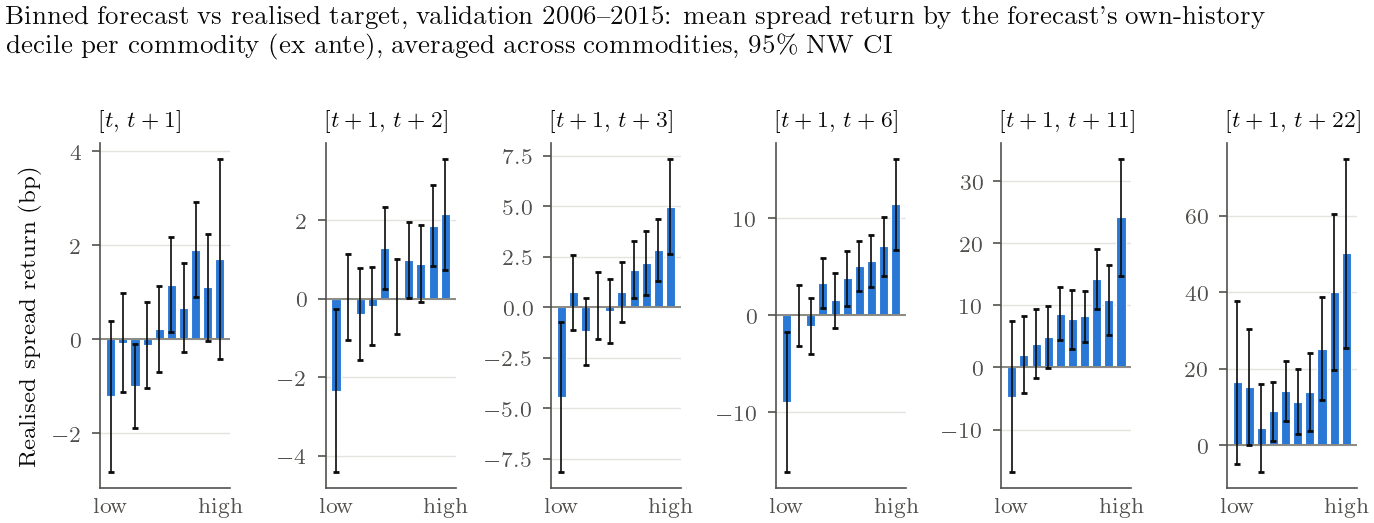

In [16]:
fig = AF.forecast_bins(bins, "validation 2006--2015")
ps.save(fig, "alpha_forecast_bins");

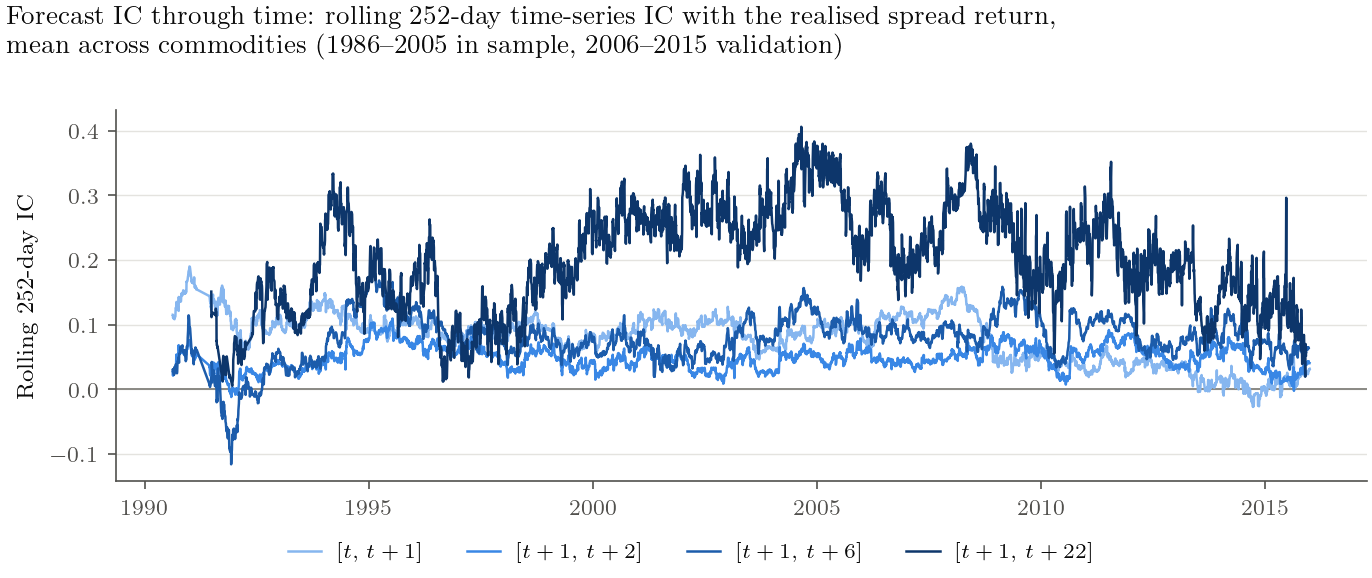

In [17]:
roll = {t: horizon.rolling_ts_ic(evalf[t][["date", "root", t]], evalf[t][["date", "root", "pred"]], col=t, score_col="pred")
        for t in ["fwd_0_1", "fwd_1_2", "fwd_1_6", "fwd_1_22"]}
fig = AF.rolling_ic(roll)
ps.save(fig, "alpha_rolling_ic");

/opt/anaconda3/lib/python3.13/site-packages/pandas/core/nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


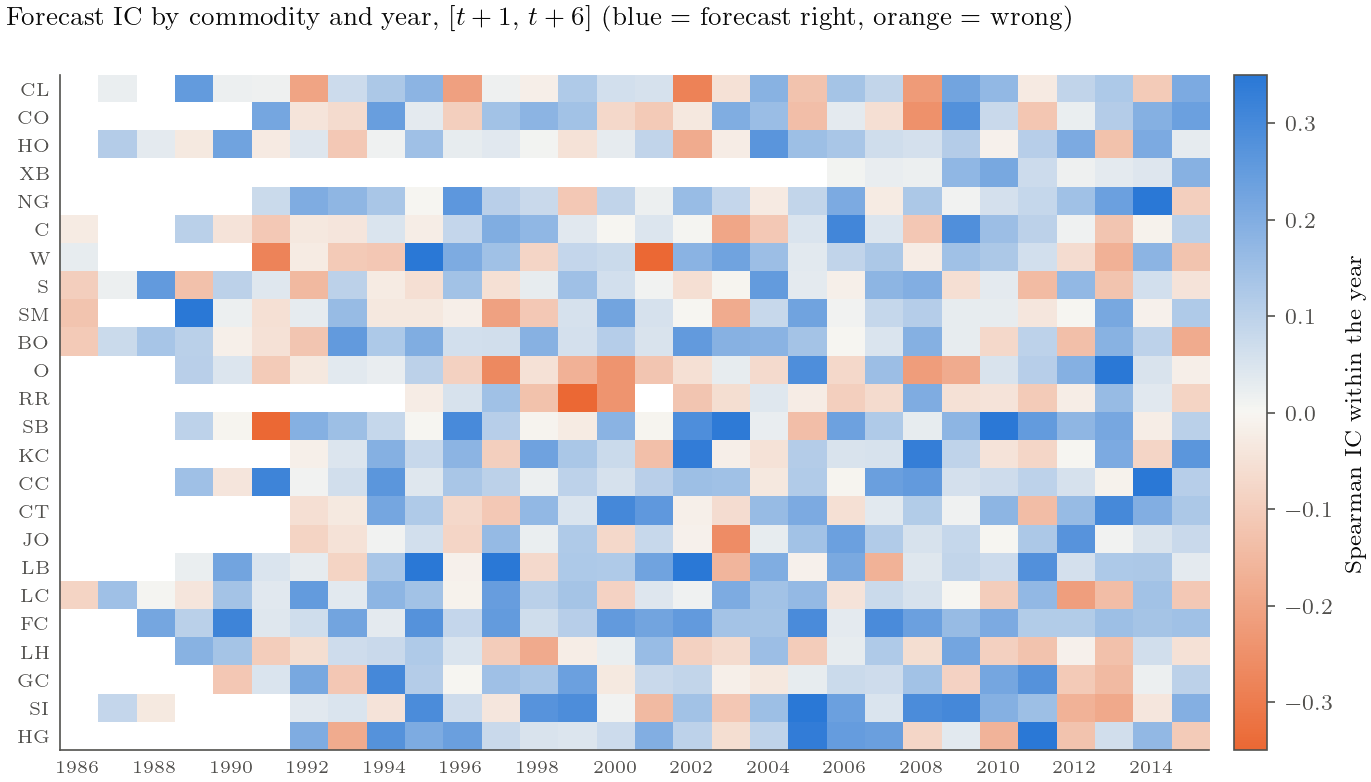

In [18]:
yic = S.yearly_ic(evalf[HEAD], "pred", HEAD)
fig = AF.yearly_root_ic(yic, HEAD, ROOT_ORDER)
ps.save(fig, "alpha_yearly_root_ic");

每个商品的预测 IC 是否显著（validation，`[t+1, t+6]`）：

significant roots: 12/24, positive: 24


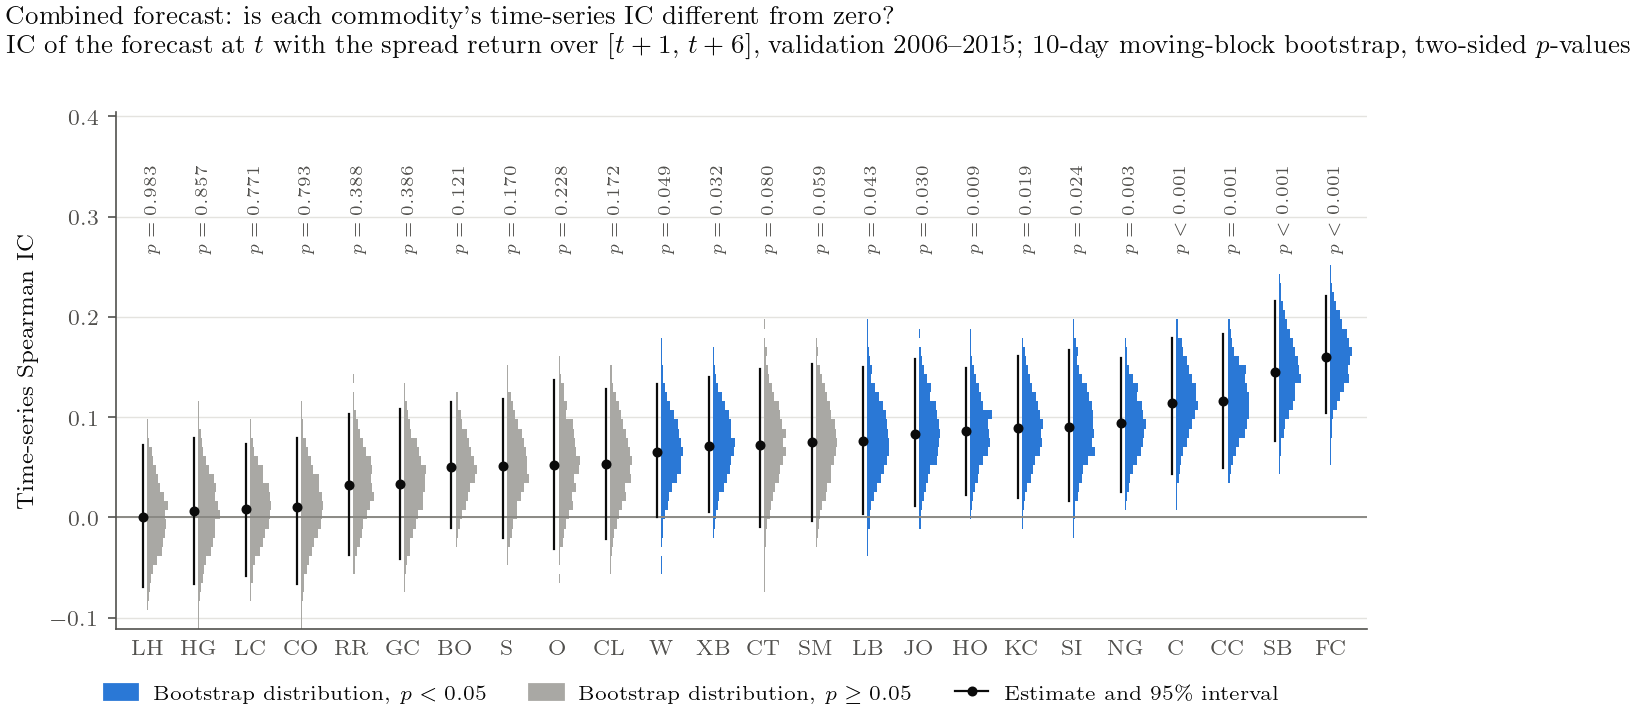

In [19]:
v = S.slice_period(evalf[HEAD], "valid")
mats = S.rank_matrices(v, ["pred"], HEAD)
boot = S.joint_bootstrap(mats, ["pred"], max(BLOCK, 5), n_boot=2000)
rtab = S.ic_table(mats, boot, "pred")
rper = rtab.loc[rtab["root"].ne("ALL")]
rdraws = {r: boot["pred"][1][:, i] for i, r in enumerate(mats["roots"]) if r in set(rper["root"])}
print(f"significant roots: {(rper['p_value'] < 0.05).sum()}/{len(rper)}, positive: {(rper['ic'] > 0).sum()}")
fig = F.bootstrap_ic_distribution(rper, rdraws, "Combined forecast", "the forecast",
                                  r"$[t+1,\,t+6]$, validation 2006--2015", max(BLOCK, 5))
ps.save(fig, "alpha_root_ic_forecast");

In [20]:
from src import v2_signals
rank = pd.read_parquet(config.PROCESSED_DIR / "rank.parquet")
inputs = v2_signals.load_v2_inputs(rank, d=5, k=5, min_adv=100)
chars = P.root_characteristics(panel, inputs.pairs, *S.PERIODS["valid"]).merge(rper[["root", "ic"]], on="root")
display(chars.round(2))

,root,log10_dollar_adv,rel_tick_bp,round_trip_bp,vol_bp,ic
0,BO,8.37,2.54,5.21,4.84,0.05
1,C,8.94,6.05,8.96,13.69,0.11
2,CC,7.93,3.76,6.91,23.80,0.12
3,CL,9.68,1.21,1.94,14.13,0.05
4,CO,9.68,1.17,1.87,9.17,0.01
5,CT,7.79,1.44,4.10,45.51,0.07
6,FC,7.80,2.04,4.09,19.54,0.16
7,GC,8.67,0.85,1.52,0.68,0.03
8,HG,8.35,1.53,2.70,6.87,0.01
9,HO,9.19,0.43,1.04,10.42,0.09


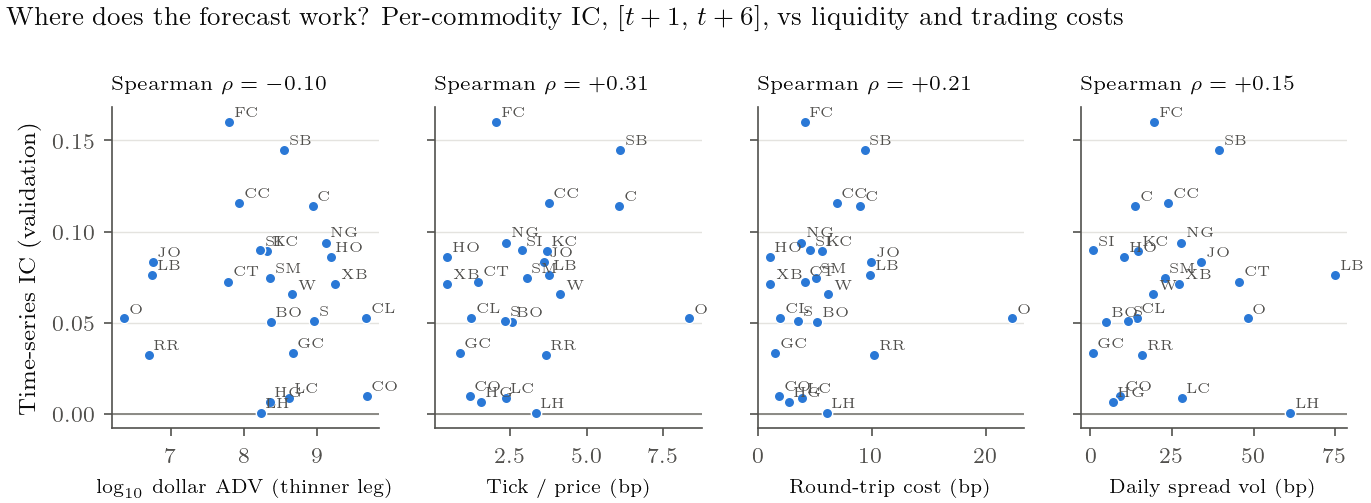

In [21]:
fig = AF.ic_vs_characteristics(chars, {"log10_dollar_adv": r"$\log_{10}$ dollar ADV (thinner leg)",
                                        "rel_tick_bp": "Tick / price (bp)",
                                        "round_trip_bp": "Round-trip cost (bp)",
                                        "vol_bp": "Daily spread vol (bp)"}, HEAD)
ps.save(fig, "alpha_ic_vs_chars");

## 6. 变现（validation，\$1m）

同一个预测，四种规则：时序 `sign`、时序 `linear`、时序 `band`（预期收益超过往返成本才换方向）、截面 `xs`（做多预测最好的 5 个、做空最差的 5 个）。持有期 k = horizon 长度（重叠 sleeve）。成本逐层扣：half-spread → fees → impact。

In [22]:
perf = pd.read_parquet(OUT / "perf_select.parquet")
v = perf.loc[perf["period"].eq("valid") & perf["layer"].isin(["gross", "- impact (all)"])]
display(v.pivot_table(index=["target", "rule"], columns="layer", values=["ann_ret_pct", "sharpe", "turnover_x"]).round(3))
print("headline TS:", SEL["ts"], "\nheadline XS:", SEL["xs"])

ann_ret_pct                sharpe            turnover_x         
layer           - impact (all)  gross - impact (all)  gross - impact (all)    gross
target   rule                                                                      
fwd_1_11 band            0.624  0.928          0.755  1.122         18.659   18.659
         linear          0.469  0.636          0.972  1.319         11.602   11.602
         sign            0.608  0.872          0.838  1.204         18.749   18.749
         xs              0.400  0.670          0.597  1.004         19.441   19.441
fwd_1_2  band           -0.338 -0.077         -0.378 -0.086         16.209   16.209
         linear          0.276  0.757          0.564  1.549         32.426   32.426
         sign           -0.190  1.300         -0.235  1.622         75.467   75.467
         xs             -1.185  1.917         -0.801  1.305        139.662  139.662
fwd_1_22 band            0.769  1.016          0.924  1.221         15.830   15.830
         linear          0.429  0.645          0.662  0.995         14.800   14.800
         sign            0.542  0.764          0.705  0.993         15.205   15.205
         xs             -0.022  0.168         -0.034  0.256         13.643   13.643
fwd_1_3  band            0.052  0.313          0.061  0.370         16.867   16.867
         linear          0.323  0.708          0.689  1.511         26.953   26.953
         sign            0.313  1.264          0.393  1.595         61.818   61.818
         xs              0.146  1.285          0.151  1.335         74.797   74.797
fwd_1_6  band            0.390  0.719          0.479  0.885         20.577   20.577
         linear          0.570  0.812          1.337  1.906         16.993   16.993
         sign            0.846  1.375          1.242  2.024         37.506   37.506
         xs              0.431  0.922          0.631  1.352         34.851   34.851

headline TS: {'target': 'fwd_1_6', 'rule': 'linear', 'valid_net_sharpe': 1.337} 
headline XS: {'target': 'fwd_1_6', 'rule': 'xs', 'valid_net_sharpe': 0.631}


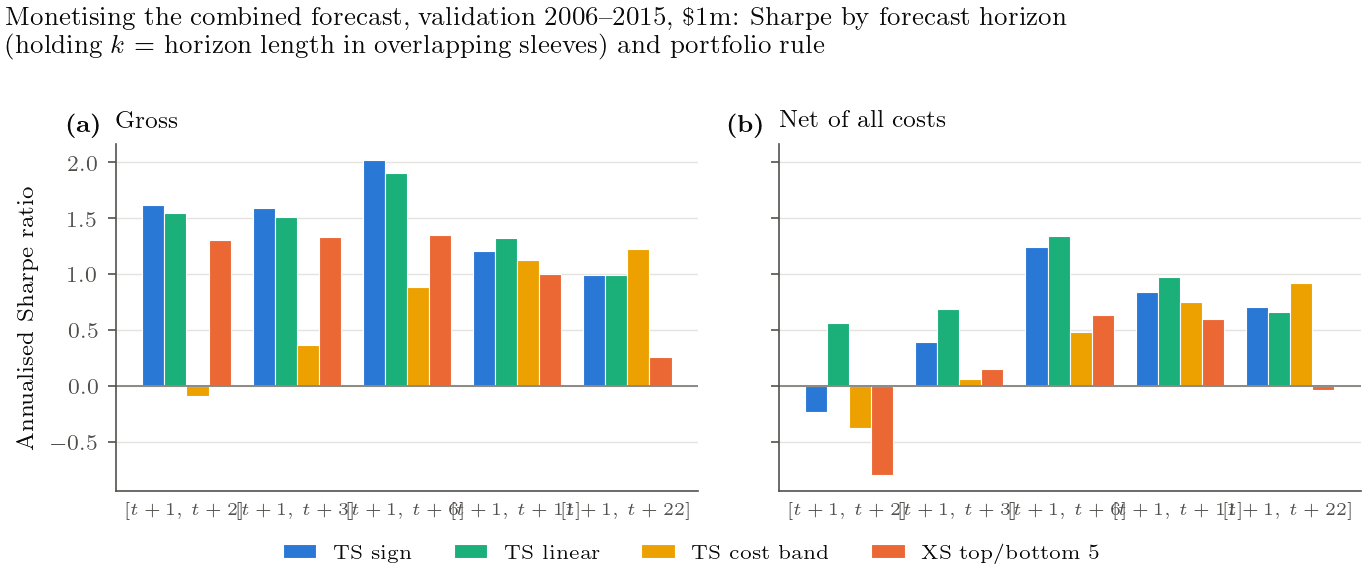

In [23]:
fig = AF.strategy_grid(perf)
ps.save(fig, "alpha_strategy_grid");

## 7. Test 2016–2026（只读一次）

选择在 validation 上冻结（`selection.json`），模型用 1986–2015 重新拟合，然后一次性跑全样本；`test_readonce.json` 记录读取时间。下表按 period 列出每层成本后的表现。

In [24]:
perf_full = pd.read_parquet(OUT / "perf_full.parquet")
with open(OUT / "results_full.pkl", "rb") as fh:
    results = pickle.load(fh)
print(json.loads((OUT / "test_readonce.json").read_text())["read_at"])
tab = perf_full.loc[perf_full["layer"].isin(["gross", "- impact (all)"])]
display(tab.pivot_table(index=["run", "period"], columns="layer", values=["ann_ret_pct", "sharpe", "t_nw"])
        .reindex(["full", "train", "valid", "test"], level=1).round(3))

2026-10-20T12:10:12.274726


ann_ret_pct                sharpe                  t_nw       
layer                 - impact (all)  gross - impact (all)  gross - impact (all)  gross
run            period                                                                  
ts_100000      full            0.069  0.438          0.114  0.725          0.686  4.373
               train           0.112  0.579          0.202  1.045          0.913  4.729
               valid           0.572  0.812          1.343  1.906          4.063  5.757
               test           -0.478 -0.168         -0.598 -0.210         -1.762 -0.619
ts_1000000     full            0.054  0.438          0.090  0.725          0.542  4.373
               train           0.088  0.579          0.159  1.045          0.719  4.729
               valid           0.570  0.812          1.337  1.906          4.044  5.757
               test           -0.486 -0.168         -0.607 -0.210         -1.792 -0.619
ts_100000_lots full           -0.003  0.001         -0.126  0.033         -1.033  0.290
               train          -0.006  0.001         -0.180  0.047         -1.033  0.290
               valid           0.000  0.000            NaN    NaN            NaN    NaN
               test            0.000  0.000            NaN    NaN            NaN    NaN
xs_1000000     full           -0.259  0.399         -0.310  0.479         -1.903  2.934
               train          -0.251  0.604         -0.312  0.755         -1.436  3.482
               valid           0.431  0.922          0.631  1.352          1.975  4.224
               test           -0.915 -0.464         -0.913 -0.462         -2.671 -1.352

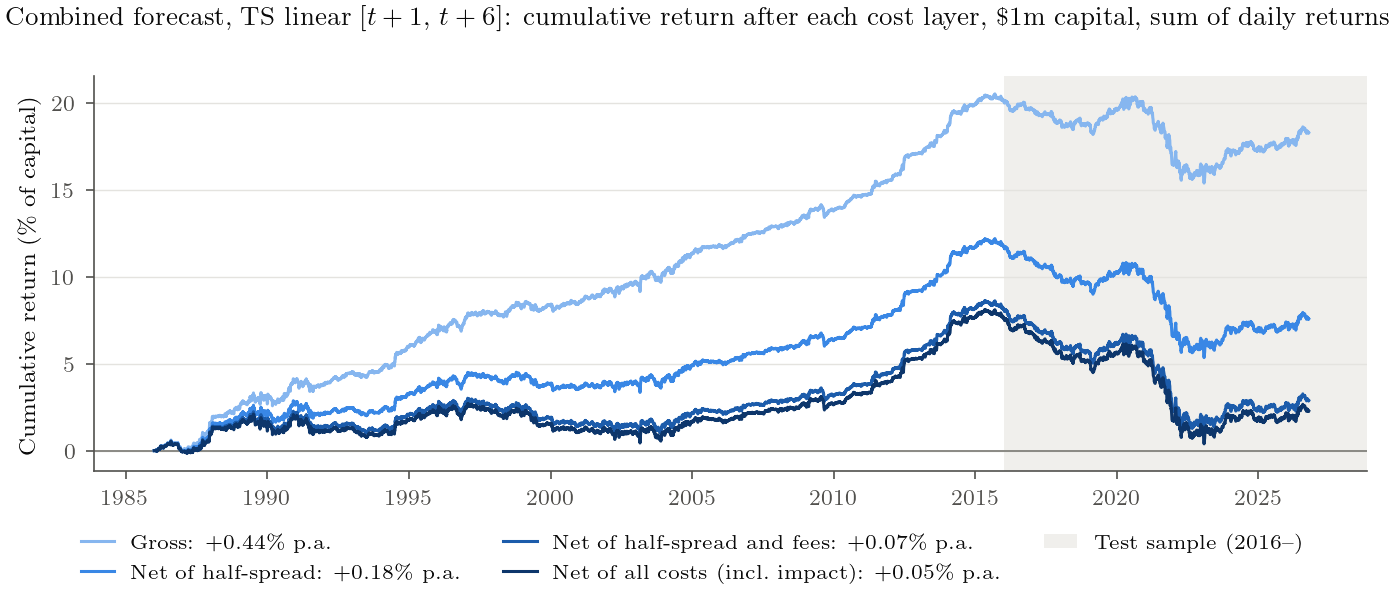

In [25]:
TS = f"Combined forecast, TS {SEL['ts']['rule']} {AF.horizon_label(SEL['ts']['target'])}"
fig = F.nav_by_cost_layer(results["ts_1000000"], TS)
ps.save(fig, "alpha_nav_ts");

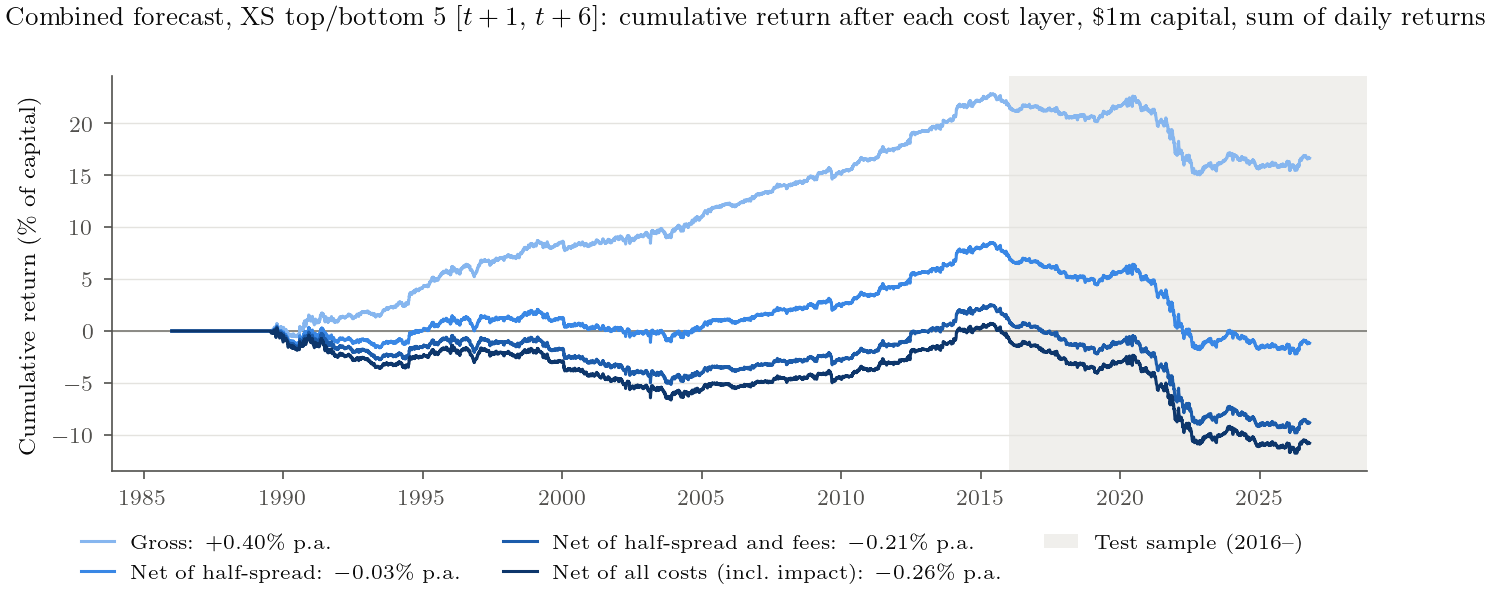

In [26]:
XS = f"Combined forecast, XS top/bottom 5 {AF.horizon_label(SEL['xs']['target'])}"
fig = F.nav_by_cost_layer(results["xs_1000000"], XS)
ps.save(fig, "alpha_nav_xs");

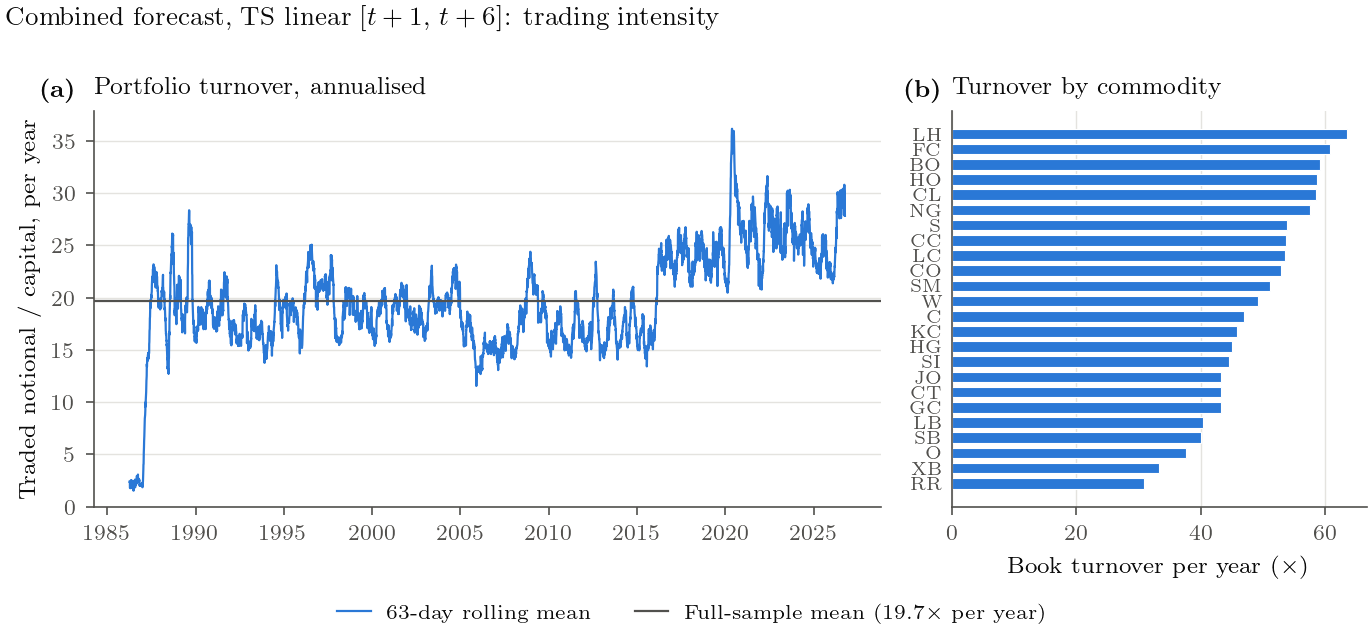

In [27]:
fig = F.turnover(results["ts_1000000"], TS)
ps.save(fig, "alpha_turnover_ts");

### 资本规模：\$100k、整手、容量曲线

half-spread 和 fee 占资本的比例不随规模变，impact 随 √资本 上升；\$100k 时整手取整会让小合约之外的品种很难精确配比。

In [28]:
small = perf_full.loc[perf_full["run"].isin(["ts_1000000", "ts_100000", "ts_100000_lots"]) & perf_full["period"].isin(["valid", "test"])]
display(small.pivot_table(index=["run", "period"], columns="layer", values="sharpe").round(3))
cap = pd.read_parquet(OUT / "capacity_ts.parquet")
display(cap.round(3))

layer              - fees  - half-spread  - impact (all)  gross
run        period                                              
ts_100000  test    -0.598         -0.474          -0.598 -0.210
           valid    1.343          1.516           1.343  1.906
ts_1000000 test    -0.598         -0.474          -0.607 -0.210
           valid    1.343          1.516           1.337  1.906

,capital,gross_bps_yr,half_spread_bps_yr,fee_bps_yr,impact_bps_yr,ann_ret_pct,sharpe
0,100000.0,43.819,25.667,11.27,0.000,0.069,0.114
1,300000.0,43.819,25.667,11.27,0.071,0.068,0.113
2,1000000.0,43.819,25.667,11.27,1.438,0.054,0.090
3,3000000.0,43.819,25.667,11.27,7.623,-0.007,-0.012
4,10000000.0,43.819,25.667,11.27,26.903,-0.200,-0.329
5,30000000.0,43.819,25.667,11.27,62.508,-0.556,-0.908


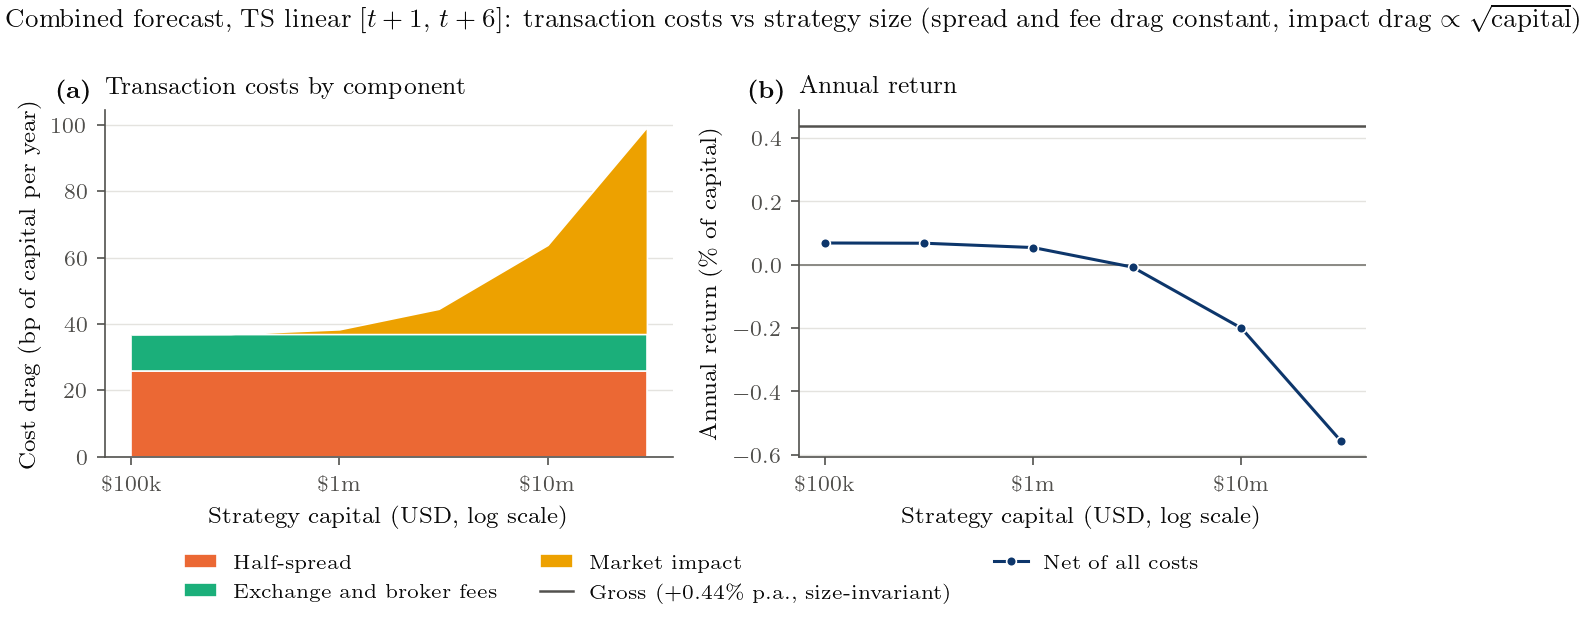

In [29]:
fig = F.capacity(cap, TS)
ps.save(fig, "alpha_capacity_ts");

### 为什么 test 亏钱：预测还在，变现被尾部品种拖垮

下面两张图只是**描述性诊断**，不参与任何选择（test 已读过一次）。先看预测本身：融合预测的 IC 在 test 期是否还在。

In [30]:
full = pd.read_parquet(OUT / "panel_full.parquet")
pf = pd.read_parquet(OUT / "preds_full.parquet").rename(columns={t: f"p_{t}" for t in af.TARGETS})
u = full.loc[full["usable"], ["date", "root"] + af.TARGETS].merge(pf, on=["date", "root"])
rows = []
for per in ("train", "valid", "test"):
    f = S.slice_period(u, per)
    for t in af.TARGETS:
        mats = S.rank_matrices(f, [f"p_{t}"], t)
        boot = S.joint_bootstrap(mats, [f"p_{t}"], max(BLOCK, int(t.split("_")[2]) - int(t.split("_")[1])), n_boot=500)
        a = S.ic_table(mats, boot, f"p_{t}").query("root == 'ALL'").iloc[0]
        rows.append(dict(period=per, target=t, ic=a["ic"], ci_lo=a["ci_lo"], ci_hi=a["ci_hi"]))
pic = pd.DataFrame(rows)
display(pic.pivot(index="target", columns="period", values="ic").reindex(af.TARGETS)[["train", "valid", "test"]].round(4))

period,train,valid,test
target,,,
fwd_0_1,0.0611,0.0208,0.0039
fwd_1_2,0.0211,0.0357,0.0149
fwd_1_3,0.0288,0.0459,0.0171
fwd_1_6,0.0392,0.0682,0.0282
fwd_1_11,0.0618,0.0953,0.0618
fwd_1_22,0.1095,0.1244,0.1412


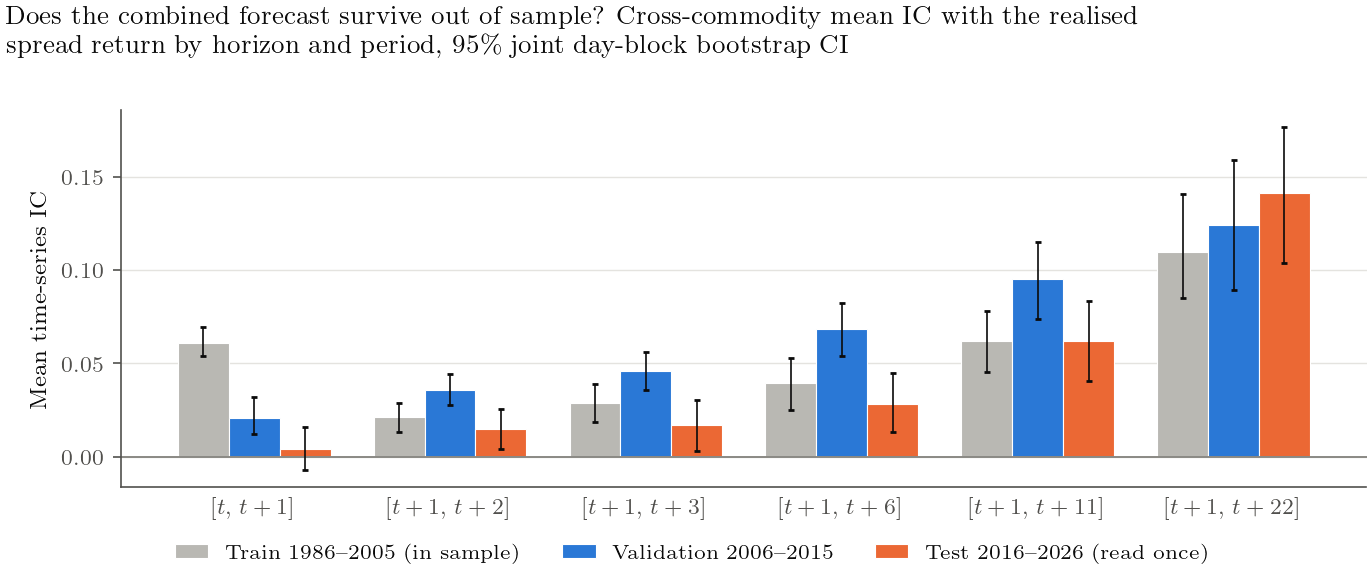

In [31]:
fig = AF.forecast_ic_periods(pic)
ps.save(fig, "alpha_ic_by_period");

test gross bp/yr: -16.8 | excluding LB: 25.5


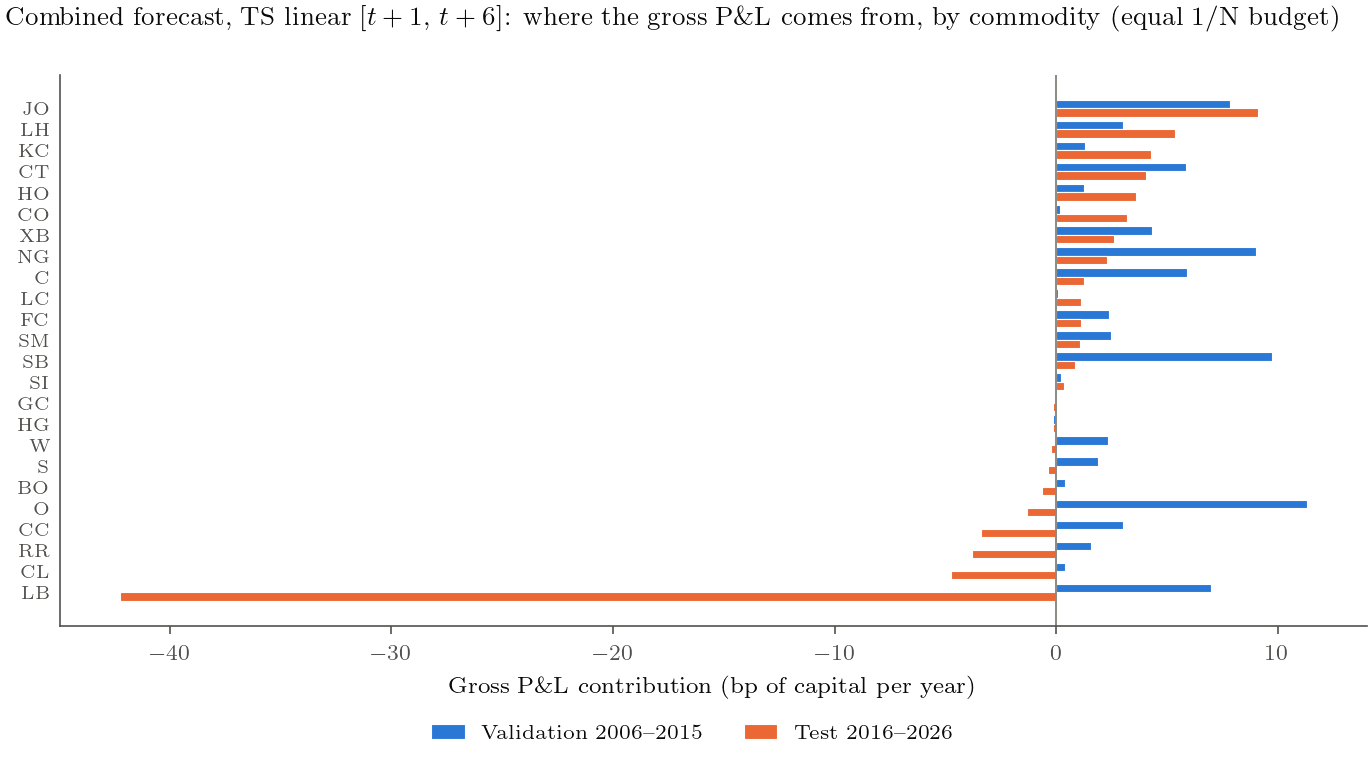

In [32]:
contrib = P.root_contribution(results["ts_1000000"], {k: S.PERIODS[k] for k in ("valid", "test")})
print("test gross bp/yr:", round(contrib["test"].sum(), 1), "| excluding LB:", round(contrib.loc[contrib["root"].ne("LB"), "test"].sum(), 1))
fig = AF.root_contribution(contrib, TS)
ps.save(fig, "alpha_root_contribution");

## 8. 结论

**信息层面，融合是成功的。** 12 个因子里，A（carry，方向与原始 A 相反）和 C（短期反转）在所有 horizon 都通过筛选，B 只在 10 天以上通过，E 只在 2–5 天勉强通过，D 在日频上一个都没过。合成之后，validation 的平均 IC 在 `[t+1, t+6]` 上是 0.068，比任何单因子都高；到了 test 期，5 天、10 天、22 天的 IC 仍然显著为正，22 天甚至升到 0.14。线性模型（OLS / Ridge / Lasso）在 paired bootstrap 里稳定地不输于 RF 和 XGBoost，XGBoost 在每个 horizon 上都没有赢过任何一个模型。

**变现层面，没有通过 test。** validation 上选出的时序头条组合（`[t+1, t+6]`、linear、\$1m）在 2006–2015 扣完全部成本后 Sharpe 1.34，但在 2016–2026 的 gross Sharpe 是 −0.21，扣完成本是 −0.61。截面对照组合同样为负。原因不是预测失效，而是 P&L 集中在少数尾部品种和尾部日子：木材（LB，2021–2022 年极端波动、2023 年停止交易）一个品种每年亏 42bp，比整个组合的亏损还多；剔除 LB，test 的 gross 是正的。等权 1/N 的仓位给了流动性很差的 LB 和原油同样的预算，而秩 IC 对这种幅度上的风险视而不见。

**规模。** half-spread 和 fee 是主要成本，impact 在 \$3m 以上才开始吞掉收益；\$100k 用整手几乎下不了单，每个品种的预算比一张合约的名义价值小得多。

**收益的量级很小。** 即使在 validation，年化收益也只有约 0.6% 的资本（波动 0.4%）：spread 收益本身就小，组合总敞口不超过 1 倍资本。Sharpe 有意义，绝对收益需要杠杆才有意义。

## 9. 下一步（需要新的 decision，test 已经用过）

- 按 √dollar ADV 加权（`scheme="liquidity"`）或按 spread 波动做风险预算，压低 LB 这类品种的权重。
- 用更长的 horizon（`[t+1, t+11]`、`[t+1, t+22]`）：IC 最强、换手最低。
- 由于 2016–2026 已经读过，任何上述改进都只能用 walk-forward 或新的保留样本来评估。